# 05 – Spread model

Can the shape of the range curve be explained by a few centres, each spreading at the same constant speed?

## Idea

Skellam (1951): a population that grows and disperses at random spreads from its starting point as a circle whose radius grows at a constant speed *c* (for large t, *c* = 2√(rD)). One centre gives a straight line for √(area) against year. Several centres that start at different times make the total √(area) bend upward while new centres appear, even though no centre spreads faster.

So the acceleration after 2010 (`04_effort-correction`: 1.6 → 4 km/yr) has two possible explanations:

1. **Faster spread:** the parakeets really spread faster after 2010.
2. **New centres:** the speed stayed the same, but populations in other cities started spreading too.

## Model

- **Centres:** London, Manchester, Birmingham, Newcastle, Nottingham, Glasgow: the largest separate clusters of persistently occupied squares on the 2025 map, each near a large city, where escaped or released pet birds are most likely (see "Choosing the centres from the 2025 map"). Cardiff, a centre in an earlier version, is weak on the map; see "Cardiff: why not a centre?".
- **Spread:** from its start year, each centre occupies a circle with radius *c* × (years since start), plus the 10 km square it lies in. A 10 km square counts as occupied when its centre lies in a circle. Overlapping circles count once; only Great Britain land squares count (the same 2,843 squares as in `04`).
- **Parameters:** one speed *c* for all centres, and one start year per centre.

Population size is not modelled: the data are presence per square, not bird counts.

## Fit

- **Data:** the effort-corrected range (`range_index.csv`), 1970–2025, atlas years (1968, 1981, 1988, 2008) left out, as in `04`. Least squares on √(area); RMSE in km of √(area).
- **Start-year bounds:** from 5 years before the first parakeet record within 25 km of the city (birds may have been there a little before they were first recorded) to 2025.
- **Search:** start years are whole years. London alone (2 parameters) is searched exhaustively. Six centres (7 parameters) use coordinate descent: each start year in turn is set to its best value with the others fixed, then the speed, until nothing improves; repeated from 40 random starting points, keeping the best.
- **Two models:** London only, and six centres.

## Caveats

- **Observer effect:** cities have more birdwatchers and more escaped cage birds. New "centres" may partly be where people look. The effort correction covers which squares were visited, not how intensively, so this is not corrected.
- Circles ignore the sea and habitat: uplands count as much as suburbs.
- Free start years make the model flexible. The fit is to the total area only, which doesn't say which city added which squares, so the start years of the smaller centres are less certain than the speed (see "How well are the parameters determined?"). Fitting the start years to the maps instead would pin them down: a possible next step.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import patheffects
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sys.path.insert(0, "../src")  # shared helpers in src/
from grid import gb_land_hectads, load_countries
from pipeline import FIRST_YEAR
import plot_style

plot_style.apply()  # presentation font sizes

PRESENCE_PATH = Path("../data/processed/presence_10km.csv.gz")   # 04_effort-correction
RANGE_INDEX_PATH = Path("../data/processed/range_index.csv")     # 04_effort-correction
LAND_PATH = Path("../data/external/ne_10m_admin_0_countries.zip")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")

LAST_YEAR = 2025                         # 2026 is incomplete
FIT_START = 1970                         # as in 04
ATLAS_START_YEARS = [1968, 1981, 1988, 2008]   # left out of the fits, as in 04
PARAKEET_LABEL = "Ring-necked Parakeet"
BENCHMARKS = ["Wren", "Robin", "Blackbird", "Blue Tit"]

# City centres, British National Grid in km (easting, northing)
CENTRES = {
    "London": (530, 180),
    "Manchester": (384, 398),
    "Birmingham": (407, 287),
    "Newcastle": (425, 565),
    "Nottingham": (457, 340),
    "Glasgow": (259, 665),
}
CARDIFF = (318, 176)  # not a centre; see "Cardiff: why not a centre?"

# Candidate cities for choosing the centres from the 2025 map
CANDIDATES = {
    **CENTRES, "Cardiff": CARDIFF,
    "Leeds": (430, 433), "Sheffield": (435, 387), "Liverpool": (335, 390), "Edinburgh": (325, 673),
    "Bristol": (359, 173), "Swansea": (265, 193), "Southampton": (442, 112), "Brighton": (531, 105),
    "East Kent": (635, 168), "Norwich": (623, 308), "Oxford": (451, 206),
}

FIRST_RECORD_RADIUS = 25  # km around the city centre for its first record
START_MARGIN = 5          # start year may be up to this many years before the first record
SPEEDS = np.arange(0.2, 8.0, 0.02)  # km/yr, grid for the speed
N_RESTARTS = 40           # random starting points for the six-centre search
SEED = 1

# Colours, as in 03 and 04
OBSERVED = plot_style.PRIMARY_DARK
LONDON_ONLY = plot_style.SECONDARY
MODEL_ONLY = plot_style.PRIMARY_LIGHT  # model only, on the maps
SIX_CENTRES = plot_style.TERTIARY
TEXT, MUTED, GRID = plot_style.TEXT, plot_style.MUTED, plot_style.GRID
LAND, LAND_EDGE = plot_style.LAND, plot_style.MUTED

## Data

- Parakeet and benchmark presence per 10 km square and year (`presence_10km.csv.gz`, Great Britain, 1963–2025).
- Effort-corrected range per year (`range_index.csv`): the curve the model is fitted to.
- Persistent squares (parakeets also the year before or after, as in `04`), for the map comparison and the persistent-squares check.

In [2]:
presence = pd.read_csv(PRESENCE_PATH)
range_index = pd.read_csv(RANGE_INDEX_PATH, index_col="year")

# All 10 km land squares in Great Britain, with their centres in km
gb_squares = sorted(gb_land_hectads(load_countries(LAND_PATH)))
gb_index = pd.Index(gb_squares)
N_GB_SQUARES = len(gb_squares)
corner = np.array([s.split("_") for s in gb_squares], dtype=float)
square_centre = corner + 5  # square ID = south-west corner in km

years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
observed = range_index.loc[years, "sqrt_area_corrected"]
fit_mask = (years >= FIT_START) & ~np.isin(years, ATLAS_START_YEARS)

parakeet = presence[presence["species"] == PARAKEET_LABEL].copy()
parakeet[["e", "n"]] = parakeet["hectad"].str.split("_", expand=True).astype(int) + 5  # square centre, km
parakeet_sets = parakeet.groupby("year")["hectad"].agg(set)

# Persistent squares (as in 04): a parakeet square counts in year t only with parakeets in t-1 or t+1 too
persistent_sets = pd.Series({
    y: {sq for sq in parakeet_sets.get(y, set())
        if sq in parakeet_sets.get(y - 1, set()) or sq in parakeet_sets.get(y + 1, set())}
    for y in years
})
print(f"{N_GB_SQUARES:,} GB land squares; {fit_mask.sum()} years in the fit "
      f"({FIT_START}–{LAST_YEAR} without {ATLAS_START_YEARS})")

2,843 GB land squares; 53 years in the fit (1970–2025 without [1968, 1981, 1988, 2008])


## Choosing the centres from the 2025 map

Which cities are centres of spread? Read from the 2025 map of persistent squares (parakeets in 2025 and also in 2024), so one-off sightings drop out:

1. **Occupation around candidate cities:** share of land squares occupied within 30 km and 50 km. A centre should sit inside a dense patch.
2. **Clusters:** occupied squares that touch (including diagonally) form a cluster; size, centre and nearest city of the largest clusters.

Only the 2025 map is used, so this shows where populations are now, not when they started.

In [3]:
land = pd.DataFrame({"e": square_centre[:, 0], "n": square_centre[:, 1]}, index=gb_index)
land["occupied"] = land.index.isin(persistent_sets[LAST_YEAR])
print(f"Persistent squares in {LAST_YEAR}: {land['occupied'].sum()}")

rows = []
for city, (x, y) in CANDIDATES.items():
    dist = np.hypot(land["e"] - x, land["n"] - y)
    row = {"city": city, "centre in model": city in CENTRES}
    for radius_km in (30, 50):
        near = dist <= radius_km
        row[f"occupied ≤{radius_km} km"] = land.loc[near, "occupied"].mean()
        row[f"squares ≤{radius_km} km"] = int(land.loc[near, "occupied"].sum())
    rows.append(row)
pd.DataFrame(rows).set_index("city").sort_values("occupied ≤30 km", ascending=False).round(2)

Persistent squares in 2025: 369


,centre in model,occupied ≤30 km,squares ≤30 km,occupied ≤50 km,squares ≤50 km
city,,,,,
London,True,1.00,32,0.96,77
Birmingham,True,0.79,22,0.43,34
East Kent,False,0.75,9,0.41,13
Manchester,True,0.72,21,0.53,41
Liverpool,False,0.50,12,0.43,28
Newcastle,True,0.46,12,0.26,16
Leeds,False,0.39,11,0.31,24
Sheffield,False,0.39,11,0.37,28
Nottingham,True,0.39,11,0.27,21


In [4]:
# Clusters: occupied squares that touch, including diagonally (8 neighbours)
occupied = land[land["occupied"]]
position = {(e, n): i for i, (e, n) in enumerate(zip(occupied["e"], occupied["n"]))}
cluster = np.full(len(occupied), -1)
for i, start in enumerate(position):
    if cluster[i] >= 0:
        continue
    cluster[i], stack = i, [start]
    while stack:
        e, n = stack.pop()
        for de in (-10, 0, 10):
            for dn in (-10, 0, 10):
                j = position.get((e + de, n + dn))
                if j is not None and cluster[j] < 0:
                    cluster[j] = i
                    stack.append((e + de, n + dn))

clusters = (occupied.assign(cluster=cluster).groupby("cluster")
            .agg(squares=("e", "size"), e=("e", "mean"), n=("n", "mean"))
            .sort_values("squares", ascending=False))


def nearest_candidate(row):
    dist = {city: np.hypot(row["e"] - x, row["n"] - y) for city, (x, y) in CANDIDATES.items()}
    city = min(dist, key=dist.get)
    return pd.Series({"nearest city": city, "km from city": dist[city]})


clusters = clusters.join(clusters.apply(nearest_candidate, axis=1)).reset_index(drop=True)
clusters.head(10).round(0)

,squares,e,n,nearest city,km from city
0,149,517.0,191.0,London,17.0
1,62,384.0,403.0,Manchester,5.0
2,30,407.0,282.0,Birmingham,5.0
3,17,433.0,552.0,Newcastle,15.0
4,16,449.0,322.0,Nottingham,19.0
5,11,625.0,160.0,East Kent,13.0
6,8,445.0,115.0,Southampton,4.0
7,6,260.0,665.0,Glasgow,1.0
8,4,390.0,350.0,Manchester,48.0
9,4,280.0,380.0,Liverpool,56.0


**Result.** The largest clusters are around London (149 squares), Manchester (62), Birmingham (30), Newcastle (17, centred 15 km south of the city), Nottingham (16, between Nottingham, Derby and Leicester), East Kent (11), Southampton (8) and Glasgow (6). The centres are London, Manchester, Birmingham, Newcastle and Nottingham, plus Glasgow: small but clearly a centre, far from the others. East Kent and Southampton are smaller and coastal, and are not used. Cardiff and Bristol have no cluster: within 30 km only 15% and 10% of squares are occupied. Leeds has 39%, against 72% for Manchester.

The centres are placed at the city coordinates, even where a cluster's centre lies 15–20 km away.

## Start-year bounds

First parakeet record within 25 km of each city, and the earliest allowed start year (5 years before it).

In [5]:
def first_record(x, y, radius=FIRST_RECORD_RADIUS):
    near = np.hypot(parakeet["e"] - x, parakeet["n"] - y) <= radius
    return int(parakeet.loc[near, "year"].min())


bounds = pd.DataFrame({"first record": {name: first_record(*xy) for name, xy in CENTRES.items()}})
bounds["earliest start"] = bounds["first record"] - START_MARGIN
bounds["latest start"] = LAST_YEAR
bounds.rename_axis("centre")

,first record,earliest start,latest start
centre,,,
London,1968,1963,2025
Manchester,1977,1972,2025
Birmingham,1984,1979,2025
Newcastle,1978,1973,2025
Nottingham,1989,1984,2025
Glasgow,1988,1983,2025


## Model and search

`occupancy(c, starts)` returns a years × squares table of occupied squares. The fit minimises the squared difference in √(area) over the fit years.

In [6]:
# Distance from every square centre to every city centre, and each city's own square
DIST = {name: np.hypot(square_centre[:, 0] - x, square_centre[:, 1] - y) for name, (x, y) in CENTRES.items()}
OWN = {name: (np.abs(square_centre[:, 0] - x) <= 5) & (np.abs(square_centre[:, 1] - y) <= 5)
       for name, (x, y) in CENTRES.items()}


def occupancy(c, starts):
    # Boolean array (years x squares): occupied with speed c (km/yr) and start years {centre: year}
    occupied = np.zeros((len(years), N_GB_SQUARES), dtype=bool)
    for name, t0 in starts.items():
        since = years - t0
        radius = np.where(since >= 0, c * since, -1.0)  # -1: not started yet
        occupied |= DIST[name][None, :] <= radius[:, None]
        occupied |= (since >= 0)[:, None] & OWN[name][None, :]
    return occupied


def model_sqrt_area(c, starts):
    return pd.Series(np.sqrt(occupancy(c, starts).sum(axis=1) * 100), index=years)


def sse(c, starts):
    return float(((model_sqrt_area(c, starts) - observed).to_numpy()[fit_mask] ** 2).sum())


def rmse_from_sse(value):
    return np.sqrt(value / fit_mask.sum())


def best_speed(starts):
    errors = [sse(c, starts) for c in SPEEDS]
    i = int(np.argmin(errors))
    return float(SPEEDS[i]), errors[i]


def coordinate_descent(starts, c=None):
    # Improve start years one at a time (and the speed, unless c is given) until nothing improves
    fixed_speed = c is not None
    if fixed_speed:
        error = sse(c, starts)
    else:
        c, error = best_speed(starts)
    while True:
        improved = False
        for name in starts:
            for t0 in range(bounds.loc[name, "earliest start"], LAST_YEAR + 1):
                trial = {**starts, name: t0}
                e = sse(c, trial)
                if e < error - 1e-9:
                    starts, error, improved = trial, e, True
        if not fixed_speed:
            c_new, e = best_speed(starts)
            if e < error - 1e-9:
                c, error, improved = c_new, e, True
        if not improved:
            return c, starts, error


def random_starts(rng, names):
    return {name: int(rng.integers(bounds.loc[name, "earliest start"], LAST_YEAR - 9)) for name in names}

## Fits

In [7]:
# London only: exhaustive over start year and speed
london_grid = [(sse(c, {"London": t0}), c, t0)
               for t0 in range(bounds.loc["London", "earliest start"], LAST_YEAR + 1) for c in SPEEDS]
error, c, t0 = min(london_grid)
fits = {"London only": {"speed": float(c), "starts": {"London": t0}, "sse": error}}

# Six centres: coordinate descent from random starting points
rng = np.random.default_rng(SEED)
solutions = [coordinate_descent(random_starts(rng, CENTRES)) for _ in range(N_RESTARTS)]
solutions.sort(key=lambda s: s[2])
c, starts, error = solutions[0]
fits["Six centres"] = {"speed": c, "starts": starts, "sse": error}


def radial_rate(series, start, end):
    # Spread rate as in 04: slope of √(area) against year, divided by √π (radius = √(area / π))
    yrs = [y for y in range(start, end + 1) if y not in ATLAS_START_YEARS]
    return np.polyfit(yrs, series.loc[yrs].to_numpy(dtype=float), 1)[0] / np.sqrt(np.pi)


def rmse_period(curve, start, end):
    yrs = [y for y in range(start, end + 1) if y not in ATLAS_START_YEARS]
    return float(np.sqrt(((curve.loc[yrs] - observed.loc[yrs]) ** 2).mean()))


curves = {name: model_sqrt_area(f["speed"], f["starts"]) for name, f in fits.items()}
rows = []
for name, f in fits.items():
    curve = curves[name]
    rows.append({
        "model": name,
        "speed c (km/yr)": f["speed"],
        **{f"start {k}": f["starts"].get(k) for k in CENTRES},
        "RMSE 1970–2025": rmse_from_sse(f["sse"]),
        "RMSE 1970–2009": rmse_period(curve, 1970, 2009),
        "RMSE 2010–2025": rmse_period(curve, 2010, 2025),
        "rate 1970–2009": radial_rate(curve, 1970, 2009),
        "rate 2010–2025": radial_rate(curve, 2010, 2025),
    })
rows.append({"model": "Observed", "rate 1970–2009": radial_rate(observed, 1970, 2009),
             "rate 2010–2025": radial_rate(observed, 2010, 2025)})
model_fits = pd.DataFrame(rows)
model_fits.to_csv(PROCESSED / "spread_model_fits.csv", index=False)
model_fits.round(2)

,model,speed c (km/yr),start London,start Manchester,start Birmingham,start Newcastle,start Nottingham,start Glasgow,RMSE 1970–2025,RMSE 1970–2009,RMSE 2010–2025,rate 1970–2009,rate 2010–2025
0,London only,2.14,1970.0,NaN,NaN,NaN,NaN,NaN,15.17,11.35,21.56,2.01,1.64
1,Six centres,1.52,1963.0,2002.0,1995.0,2004.0,2003.0,1996.0,8.09,7.15,9.93,1.65,3.07
2,Observed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.64,4.03


In [8]:
# Spread rate by window: the stall after Bird Atlas 2007–11 makes the recent rate depend on where it starts.
# Share explained = the six-centre model's own speed-up divided by the observed speed-up, each measured
# against the rate from 1970 to the year before the window. No London-only model is needed for this:
# a London-only fit has one speed for the whole period, so it is too fast before 2010 and too slow after.
# The London-only rate and the share relative to it are kept for comparison.
WINDOWS = [(2010, LAST_YEAR), (2007, LAST_YEAR), (2005, LAST_YEAR)]


def window_table(obs, six, london):
    rows = []
    for start, end in WINDOWS:
        row = {"window": f"{start}–{end}",
               "observed before": radial_rate(obs, FIT_START, start - 1),
               "observed": radial_rate(obs, start, end),
               "six centres before": radial_rate(six, FIT_START, start - 1),
               "six centres": radial_rate(six, start, end),
               "London only": radial_rate(london, start, end)}
        row["share of speed-up explained"] = ((row["six centres"] - row["six centres before"])
                                              / (row["observed"] - row["observed before"]))
        row["share vs London-only fit"] = ((row["six centres"] - row["London only"])
                                           / (row["observed"] - row["London only"]))
        rows.append(row)
    return pd.DataFrame(rows).set_index("window")


windows = window_table(observed, curves["Six centres"], curves["London only"])
windows.round(2)

,observed before,observed,six centres before,six centres,London only,share of speed-up explained,share vs London-only fit
window,,,,,,,
2010–2025,1.64,4.03,1.65,3.07,1.64,0.59,0.60
2007–2025,1.58,3.50,1.61,2.99,1.65,0.72,0.73
2005–2025,1.54,3.22,1.59,2.93,1.73,0.80,0.81


### Curves

`spread_model_curves.png` (observed, London only, six centres) and `spread_model_curves_six_centres.png` (without London only).

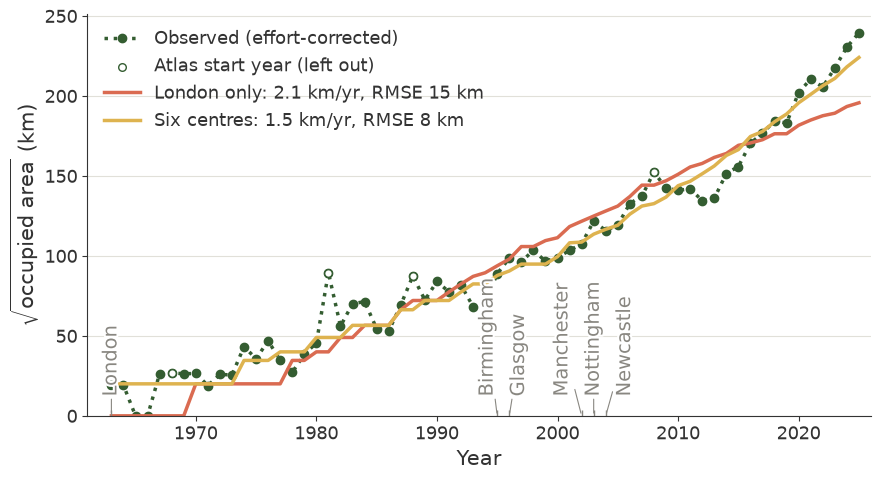

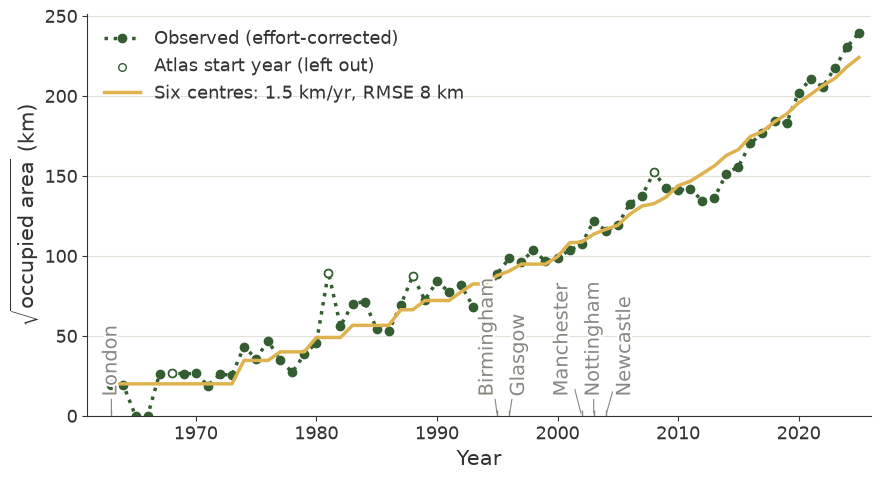

In [9]:
# Start-year labels: spread apart so that neighbouring names keep at least MIN_GAP years between them,
# each joined to its start-year tick by a thin line where it had to move
START_LABEL_SIZE = 14
MIN_GAP = 2.6  # years between label centres (rotated 14 pt text is about 2 years wide here)


def spread_positions(xs, min_gap):
    """Positions as close as possible to xs (sorted), at least min_gap apart; crowded groups centred."""
    groups = [[x] for x in xs]  # each group: original positions, laid out centred on their mean
    merged = True
    while merged:
        merged = False
        for i in range(len(groups) - 1):
            a, b = groups[i], groups[i + 1]
            a_end = np.mean(a) + (len(a) - 1) / 2 * min_gap
            b_start = np.mean(b) - (len(b) - 1) / 2 * min_gap
            if b_start - a_end < min_gap:
                groups[i:i + 2] = [a + b]
                merged = True
                break
    return [np.mean(g) + (k - (len(g) - 1) / 2) * min_gap for g in groups for k in range(len(g))]


def plot_curves(models, filename):
    """Observed range with the fitted model curves in `models` (names in `fits`) and the six start years."""
    fig, ax = plt.subplots(figsize=(9, 5))

    used = ~observed.index.isin(ATLAS_START_YEARS)
    ax.plot(observed.index, observed, ":o", color=OBSERVED, linewidth=2.5, label="Observed (effort-corrected)")
    ax.scatter(observed.index[~used], observed[~used], facecolors="white", edgecolors=OBSERVED,
               s=30, zorder=3, label="Atlas start year (left out)")

    colours = {"London only": LONDON_ONLY, "Six centres": SIX_CENTRES}
    for name in models:
        f = fits[name]
        ax.plot(curves[name].index, curves[name], color=colours[name], linewidth=2.5,
                label=f"{name}: {f['speed']:.1f} km/yr, RMSE {rmse_from_sse(f['sse']):.0f} km")

    starts = sorted(fits["Six centres"]["starts"].items(), key=lambda item: item[1])
    label_x = spread_positions([t0 for _, t0 in starts], MIN_GAP)
    for (name, t0), x in zip(starts, label_x):
        ax.plot([t0], [0], marker="|", color=MUTED, markersize=8)
        ax.annotate(name, xy=(t0, 0), xytext=(x, 14), textcoords=("data", "offset points"), rotation=90,
                    ha="center", va="bottom", fontsize=START_LABEL_SIZE, color=MUTED,
                    arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8, shrinkA=0, shrinkB=2),
                    path_effects=[patheffects.withStroke(linewidth=3, foreground="white")])

    ax.set_xlim(FIRST_YEAR - 2, LAST_YEAR + 1)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Year")
    ax.set_ylabel(r"$\sqrt{\text{occupied area}}$ (km)")
    #ax.set_title(f"Constant-speed spread from one or six centres, fitted to {FIT_START}–{LAST_YEAR}")
    ax.legend(frameon=False, loc="upper left", fontsize=13)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    fig.savefig(FIGURES / filename, dpi=200)
    plt.show()


plot_curves(["London only", "Six centres"], "spread_model_curves.png")
plot_curves(["Six centres"], "spread_model_curves_six_centres.png")  # without London only

## How well are the parameters determined?

1. **Near-best solutions:** the six-centre searches that end within 5% of the best RMSE. If their start years differ widely, the data don't determine them.
2. **Speed profile:** for each fixed speed, the best RMSE over the start years. A narrow dip means the speed is well determined. For London exhaustively; for six centres by coordinate descent from the best solution and 3 random starting points per speed.

In [10]:
best_rmse = rmse_from_sse(solutions[0][2])
near_best = pd.DataFrame([{"speed c (km/yr)": c, **s, "RMSE": rmse_from_sse(e)}
                          for c, s, e in solutions if rmse_from_sse(e) <= 1.05 * best_rmse])
near_best = near_best.drop_duplicates()
print(f"{len(near_best)} of {N_RESTARTS} searches within 5% of the best RMSE ({best_rmse:.2f} km)")
display(near_best.round(2))
near_best.agg(["min", "max"]).round(2)

3 of 40 searches within 5% of the best RMSE (8.09 km)


,speed c (km/yr),London,Manchester,Birmingham,Newcastle,Nottingham,Glasgow,RMSE
0,1.52,1963,2002,1995,2004,2003,1996,8.09
1,1.50,1963,2001,2006,2006,1990,1997,8.17
2,1.50,1963,2006,2005,1991,1996,1997,8.37


,speed c (km/yr),London,Manchester,Birmingham,Newcastle,Nottingham,Glasgow,RMSE
min,1.50,1963,2001,1995,1991,1990,1996,8.09
max,1.52,1963,2006,2006,2006,2003,1997,8.37


speed,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,...,2.1,2.2,2.3,2.4,2.5,2.6,2.7,2.8,2.9,3.0
London only,67.94,61.68,55.19,48.46,42.48,35.59,29.81,24.70,20.85,17.97,...,15.29,15.58,16.12,16.75,17.80,18.82,19.60,20.96,22.35,23.29
Six centres,26.21,16.77,12.01,11.06,10.84,9.78,9.43,8.16,8.43,9.12,...,11.20,12.58,13.84,15.05,13.61,17.97,18.99,14.21,14.89,23.23


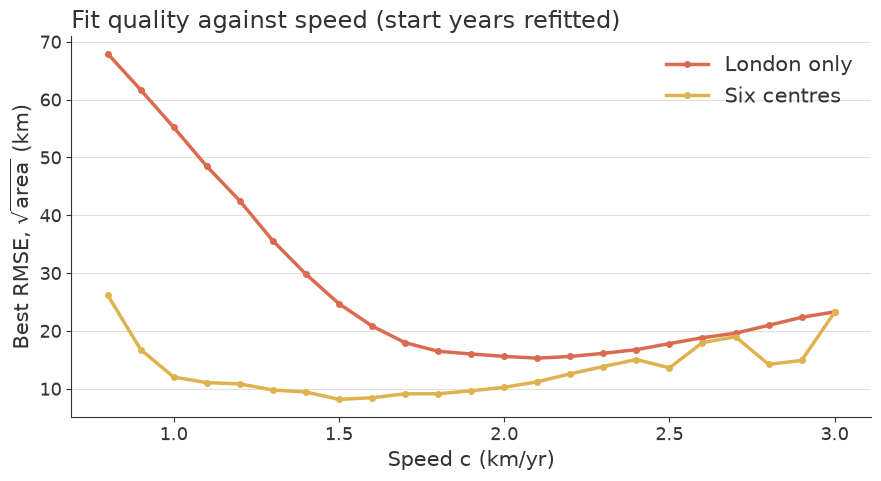

In [11]:
PROFILE_SPEEDS = np.arange(0.8, 3.01, 0.1)
profile_rng = np.random.default_rng(SEED)
london_errors = pd.DataFrame(london_grid, columns=["sse", "speed", "start"])

profile = []
for c in PROFILE_SPEEDS:
    london_best = london_errors.loc[np.isclose(london_errors["speed"], c), "sse"].min()
    inits = [fits["Six centres"]["starts"]] + [random_starts(profile_rng, CENTRES) for _ in range(3)]
    six_best = min(coordinate_descent(s, c=c)[2] for s in inits)
    profile.append({"speed": c, "London only": rmse_from_sse(london_best), "Six centres": rmse_from_sse(six_best)})
profile = pd.DataFrame(profile).set_index("speed")

fig, ax = plt.subplots(figsize=(9, 5))
for name, colour in [("London only", LONDON_ONLY), ("Six centres", SIX_CENTRES)]:
    ax.plot(profile.index, profile[name], color=colour, linewidth=2.5, marker="o", markersize=4, label=name)
ax.set_xlabel("Speed c (km/yr)")
ax.set_ylabel(r"Best RMSE, $\sqrt{\text{area}}$ (km)")
ax.set_title("Fit quality against speed (start years refitted)")
ax.legend(frameon=False)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "spread_model_speed_profile.png", dpi=200)
profile.round(2).T

## Maps: model against observed squares

Six-centre fit against the squares with parakeet records in the same year (not effort-corrected; before about 2008 many squares were not visited, so "model only" is inflated in 1990 and 2005).

The four-year overview is `spread_model_maps.png`; one figure per year (1990, 1995, …, 2025) is `spread_model_map_<year>.png`.

In [12]:
MAP_YEARS = [1990, 2005, 2015, 2025]
model = fits["Six centres"]
model_occupancy = occupancy(model["speed"], model["starts"])


def model_set(year):
    return set(gb_index[model_occupancy[years == year][0]])


rows = []
for year in MAP_YEARS:
    m = model_set(year)
    for obs_name, sets in [("all", parakeet_sets), ("persistent", persistent_sets)]:
        o = sets.get(year, set()) & set(gb_index)
        rows.append({
            "year": year, "observed squares": obs_name,
            "model": len(m), "observed": len(o), "both": len(m & o),
            "share of observed inside model": len(m & o) / len(o),
            "share of model observed": len(m & o) / len(m),
        })
map_comparison = pd.DataFrame(rows)
map_comparison.round(2)

,year,observed squares,model,observed,both,share of observed inside model,share of model observed
0,1990,all,52,35,14,0.40,0.27
1,1990,persistent,52,17,11,0.65,0.21
2,2005,all,142,121,53,0.44,0.37
3,2005,persistent,142,83,46,0.55,0.32
4,2015,all,277,224,112,0.50,0.40
5,2015,persistent,277,161,99,0.61,0.36
6,2025,all,502,543,281,0.52,0.56
7,2025,persistent,502,369,237,0.64,0.47


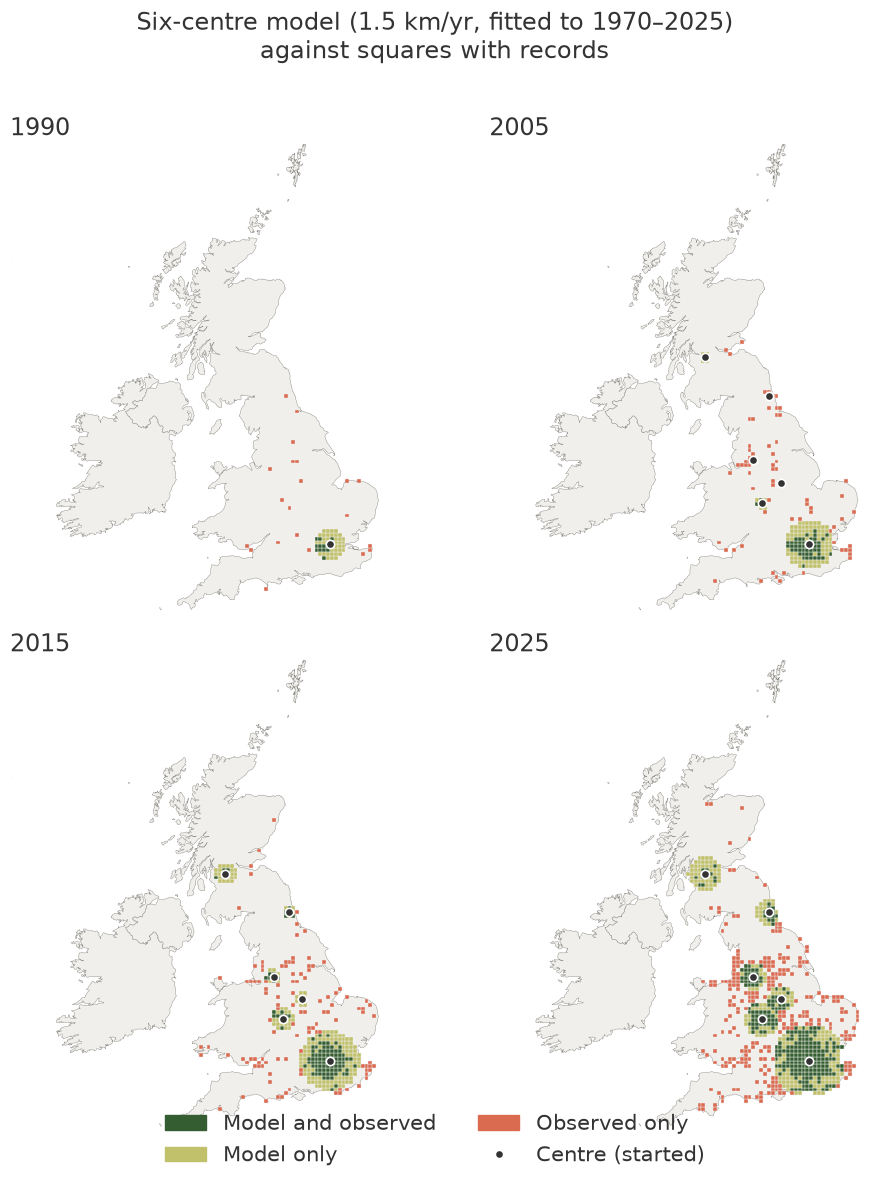

Saved spread_model_map_<year>.png for [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025]


In [13]:
# One polygon per GB land square (km), for drawing
import geopandas as gpd
from shapely.geometry import box

square_polys = gpd.GeoSeries([box(e, n, e + 10, n + 10) for e, n in corner], index=gb_index)
countries = load_countries(LAND_PATH)
land = (countries[countries["ADM0_A3"].isin(["GBR", "IRL", "IMN"])].to_crs("EPSG:27700")
        .geometry.scale(xfact=0.001, yfact=0.001, origin=(0, 0)))  # metres -> km
xmin, ymin = corner.min(axis=0)
xmax, ymax = corner.max(axis=0) + 10

CATEGORIES = [("both", "Model and observed", OBSERVED),
              ("model", "Model only", MODEL_ONLY),
              ("observed", "Observed only", LONDON_ONLY)]

# Centre dots with a white outline, so they show on dark squares
CENTRE_MARKER = dict(marker="o", color=TEXT, markeredgecolor="white", markeredgewidth=1.2)


def draw_model_map(ax, year, marker_size):
    """Model against observed squares in one year, with the centres that have started."""
    m = model_set(year)
    o = parakeet_sets.get(year, set()) & set(gb_index)
    groups = {"both": m & o, "model": m - o, "observed": o - m}

    land.plot(ax=ax, color=LAND, edgecolor=LAND_EDGE, linewidth=0.3)
    for key, _, colour in CATEGORIES:
        if groups[key]:
            square_polys.loc[sorted(groups[key])].plot(ax=ax, color=colour, edgecolor=LAND, linewidth=0.3)
    for name, (x, y) in CENTRES.items():
        if year >= model["starts"][name]:
            ax.plot(x, y, markersize=marker_size, zorder=5, **CENTRE_MARKER)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_axis_off()


def legend_handles(marker_size):
    handles = [Patch(color=colour, label=label) for _, label, colour in CATEGORIES]
    handles.append(Line2D([], [], linestyle="", markersize=marker_size, label="Centre (started)", **CENTRE_MARKER))
    return handles


# Overview: four years in one figure
fig, axes = plt.subplots(2, 2, figsize=(10, 12))
for ax, year in zip(axes.ravel(), MAP_YEARS):
    draw_model_map(ax, year, marker_size=6)
    ax.set_title(str(year), fontsize=17, color=TEXT)

fig.legend(handles=legend_handles(6), loc="lower center", ncol=2, frameon=False, fontsize=15)
fig.suptitle(f"Six-centre model ({model['speed']:.1f} km/yr, fitted to {FIT_START}–{LAST_YEAR})\n"
             "against squares with records", fontsize=17, color=TEXT)
plt.tight_layout(rect=(0, 0.03, 1, 0.97))
fig.savefig(FIGURES / "spread_model_maps.png", dpi=200)
plt.show()

# One figure per year, for the slides
SINGLE_MAP_YEARS = range(1990, LAST_YEAR + 1, 5)
for year in SINGLE_MAP_YEARS:
    fig, ax = plt.subplots(figsize=(6, 7.5))
    draw_model_map(ax, year, marker_size=8)
    ax.set_title(str(year), fontsize=20, color=TEXT, loc="left")
    ax.legend(handles=legend_handles(8), loc="lower left", frameon=False, fontsize=13)
    plt.tight_layout()
    fig.savefig(FIGURES / f"spread_model_map_{year}.png", dpi=200)
    plt.close(fig)
print(f"Saved spread_model_map_<year>.png for {list(SINGLE_MAP_YEARS)}")

## Squares the model doesn't reach

Observed squares in 2025 outside the six-centre model, grouped by the nearest of a longer list of cities (within 40 km). Clusters of persistent squares here are candidates for further centres; scattered single squares are more likely wandering birds or one-off records.

In [14]:
OTHER_CITIES = CANDIDATES

model_2025 = model_set(LAST_YEAR)
outside = pd.DataFrame({"hectad": sorted(parakeet_sets[LAST_YEAR] & set(gb_index) - model_2025)})
outside[["e", "n"]] = outside["hectad"].str.split("_", expand=True).astype(int) + 5
outside["persistent"] = outside["hectad"].isin(persistent_sets[LAST_YEAR])


def nearest_city(row, max_km=40):
    dist = {name: np.hypot(row["e"] - x, row["n"] - y) for name, (x, y) in OTHER_CITIES.items()}
    name = min(dist, key=dist.get)
    return name if dist[name] <= max_km else "elsewhere"


outside["near"] = outside.apply(nearest_city, axis=1)
print(f"{len(outside)} of {len(parakeet_sets[LAST_YEAR] & set(gb_index))} observed squares in {LAST_YEAR} "
      f"are outside the model; {outside['persistent'].sum()} of them persistent")
(outside.groupby("near").agg(squares=("hectad", "size"), persistent=("persistent", "sum"))
 .sort_values("squares", ascending=False))

262 of 543 observed squares in 2025 are outside the model; 132 of them persistent


,squares,persistent
near,,
elsewhere,144,62
Liverpool,17,12
Leeds,16,11
Southampton,16,9
Sheffield,13,9
Bristol,12,3
Norwich,11,4
East Kent,9,8
Cardiff,8,4


## Cardiff: why not a centre?

Cardiff has parakeet records from 1972 but few occupied squares around it in 2025 (see "Choosing the centres from the 2025 map"); as a centre in an earlier version of the model, its circle stayed mostly empty. Are the occupied squares near Cardiff concentrated on the coast rather than spread in a circle?

1. **Coast:** distance from each square's centre to the coast (Natural Earth outline; centres in the sea count as 0 km). Squares with parakeet records in at least 2 years within 80 km of Cardiff, against all land squares within 80 km.
2. **Timing:** first parakeet year of each occupied square on the Welsh side (a box west of the Severn, 200–335 km east, 150–260 km north). A front moving along the coast would reach Swansea (55–65 km west) decades after Cardiff.
3. **Recording effort:** coastal squares may simply have more birdwatchers. Proxy: GBIF benchmark records per square, 2010–2025 (`gbif_benchmark_squares.csv.gz`; NBN has no record counts here). Welsh-side squares are split into thirds by this effort, and coastal and inland squares are compared within each third.

In [15]:
import shapely

GBIF_BENCH_PATH = Path("../data/processed/gbif_benchmark_squares.csv.gz")  # 04_effort-correction
COAST_KM = 5  # "coastal" = square centre within 5 km of the coast

uk = countries.loc[countries["ADM0_A3"] == "GBR"].to_crs("EPSG:27700").geometry.union_all()
points = shapely.points(square_centre * 1000)
coast_km = np.where(shapely.contains(uk, points), shapely.distance(points, uk.boundary) / 1000, 0)

squares = pd.DataFrame({"e": square_centre[:, 0], "n": square_centre[:, 1], "coast_km": coast_km},
                       index=gb_index)
cx, cy = CARDIFF
squares["km_from_cardiff"] = np.hypot(squares["e"] - cx, squares["n"] - cy)
squares["first_year"] = parakeet.groupby("hectad")["year"].min()

rows = []
for start, end in [(1972, 2009), (2010, LAST_YEAR)]:
    n_years = parakeet[parakeet["year"].between(start, end)].groupby("hectad")["year"].nunique()
    ring = squares[squares["km_from_cardiff"] <= 80]
    occupied = ring[ring.index.map(n_years).fillna(0) >= 2]
    rows.append({
        "period": f"{start}–{end}",
        "land squares": len(ring),
        "occupied (2+ years)": len(occupied),
        f"occupied within {COAST_KM} km of coast": (occupied["coast_km"] <= COAST_KM).mean(),
        f"land within {COAST_KM} km of coast": (ring["coast_km"] <= COAST_KM).mean(),
        "median coast km, occupied": occupied["coast_km"].median(),
        "median coast km, land": ring["coast_km"].median(),
    })
pd.DataFrame(rows).set_index("period").round(2)

,land squares,occupied (2+ years),occupied within 5 km of coast,land within 5 km of coast,"median coast km, occupied","median coast km, land"
period,,,,,,
1972–2009,189,29,0.55,0.21,3.79,18.72
2010–2025,189,47,0.32,0.21,9.77,18.72


In [16]:
# Welsh side: occupied squares (records in 2+ years, all years) by first parakeet year
wales = squares[squares["e"].between(200, 335) & squares["n"].between(150, 260)].copy()
wales["n_years"] = wales.index.map(parakeet.groupby("hectad")["year"].nunique()).fillna(0)
wales["occupied"] = wales["n_years"] >= 2
wales["coastal"] = wales["coast_km"] <= COAST_KM

print(f"{wales['occupied'].sum()} of {len(wales)} Welsh-side squares occupied; first 10 by first year:")
(wales[wales["occupied"]].sort_values("first_year")
 [["first_year", "n_years", "coast_km", "km_from_cardiff"]].head(10).round(1))

30 of 125 Welsh-side squares occupied; first 10 by first year:


,first_year,n_years,coast_km,km_from_cardiff
330_160,1972.0,9.0,1.7,20.2
310_170,1974.0,27.0,4.0,3.2
320_170,1975.0,8.0,0.0,7.1
310_180,1980.0,15.0,10.7,9.5
310_160,1980.0,15.0,0.0,11.4
250_190,1981.0,7.0,0.4,65.8
250_200,1981.0,3.0,5.5,69.4
260_190,1981.0,17.0,2.3,56.3
310_220,1981.0,2.0,43.4,49.1
290_180,1983.0,5.0,13.2,24.7


In [17]:
# Recording effort: GBIF benchmark records per square, 2010–2025
gbif_bench = pd.read_csv(GBIF_BENCH_PATH)
effort = gbif_bench[gbif_bench["year"].between(2010, LAST_YEAR)].groupby("hectad")["n_records"].sum()
wales["benchmark_records"] = wales.index.map(effort).fillna(0)
wales["effort third"] = pd.qcut(wales["benchmark_records"], 3, labels=["low", "middle", "high"])

display(wales.groupby("coastal").agg(squares=("occupied", "size"),
                                     median_benchmark_records=("benchmark_records", "median"),
                                     share_occupied=("occupied", "mean")).round(2))
(wales.groupby(["effort third", "coastal"], observed=True)
 .agg(squares=("occupied", "size"), share_occupied=("occupied", "mean")).round(2))

,squares,median_benchmark_records,share_occupied
coastal,,,
False,84,311.5,0.20
True,41,801.0,0.32


squares  share_occupied
effort third coastal                         
low          False         33            0.06
             True           9            0.00
middle       False         26            0.12
             True          15            0.20
high         False         25            0.48
             True          17            0.59

**Result.**

- **Not a circle, but the coastal belt.** Before 2010, 55% of the occupied squares within 80 km of Cardiff are within 5 km of the coast, against 21% of all land squares (median 4 km against 19 km). From 2010 the bias is weaker (32%), partly because squares around Bristol, across the Severn, fill in. The valleys and uplands north of Cardiff stay almost empty for 50 years.
- **Not a front along the coast.** The Swansea squares, 55–65 km from Cardiff, are occupied by 1983 at the latest: Winter Atlas records (1981–84), then local records from 1983 (INNS Data, NRW). That is about ten years after Cardiff's first records, so about 6 km/yr, far faster than the fitted speed. A separate population, or birds moving between coastal towns, fits better than gradual spread.
- **Coast, towns and birdwatchers coincide.** Coastal squares on the Welsh side have about 2.6 times as many benchmark records as inland squares. Within the same effort third, the coastal excess is small (e.g. 59% against 48% occupied in the top third), and each group has only 9–33 squares.

So the Cardiff population stayed in the coastal urban belt and hardly spread inland, which is why it is not a centre of spread in the model. These data can't separate coast, towns and observer effort.

## Check: fit to persistent squares

The model is fitted to the effort-corrected range from all squares with parakeet records. One-off sightings (wandering birds, single visits, eBird reaching new areas) count there too. As a check, the same fits use the range from **persistent squares** only: a square counts in year t only if parakeets were also recorded there in t−1 or t+1, as in the check in `04` (1.34 → 4.03 km/yr there). Same centres, start-year bounds, search and seed.

Persistence itself depends on recording effort (a square has to be recorded in two neighbouring years, which is less likely when few squares are visited), so the early part of this curve is lower than the main one. The question is only whether new centres still account for most of the speed-up.

In [18]:
# Effort-corrected range from persistent squares only (as the "Persistent squares" check in 04)
visited_sets = presence[presence["species"].isin(BENCHMARKS)].groupby("year")["hectad"].agg(set)
persistent_index = pd.Series({
    y: len(persistent_sets[y] & visited_sets[y]) / len(visited_sets[y]) if visited_sets.get(y) else np.nan
    for y in years
})
persistent_curve = np.sqrt(persistent_index * N_GB_SQUARES * 100)

# Same fits as above. sse, radial_rate and rmse_period compare with the global `observed`,
# so it is swapped for the persistent curve here and restored afterwards.
main_observed = observed
observed = persistent_curve
try:
    london_grid_p = [(sse(c, {"London": t0}), c, t0)
                     for t0 in range(bounds.loc["London", "earliest start"], LAST_YEAR + 1) for c in SPEEDS]
    error, c, t0 = min(london_grid_p)
    fits_p = {"London only": {"speed": float(c), "starts": {"London": t0}, "sse": error}}

    rng_p = np.random.default_rng(SEED)
    solutions_p = sorted((coordinate_descent(random_starts(rng_p, CENTRES)) for _ in range(N_RESTARTS)),
                         key=lambda s: s[2])
    c, starts, error = solutions_p[0]
    fits_p["Six centres"] = {"speed": c, "starts": starts, "sse": error}
    curves_p = {name: model_sqrt_area(f["speed"], f["starts"]) for name, f in fits_p.items()}

    rows = []
    for name, f in fits_p.items():
        rows.append({"model": name, "speed c (km/yr)": f["speed"],
                     **{f"start {k}": f["starts"].get(k) for k in CENTRES},
                     "RMSE 1970–2025": rmse_from_sse(f["sse"]),
                     "rate 1970–2009": radial_rate(curves_p[name], 1970, 2009),
                     "rate 2010–2025": radial_rate(curves_p[name], 2010, 2025)})
    rows.append({"model": "Observed (persistent)", "rate 1970–2009": radial_rate(persistent_curve, 1970, 2009),
                 "rate 2010–2025": radial_rate(persistent_curve, 2010, 2025)})
    model_fits_p = pd.DataFrame(rows)

    windows_p = window_table(persistent_curve, curves_p["Six centres"], curves_p["London only"])
finally:
    observed = main_observed

model_fits_p.to_csv(PROCESSED / "spread_model_fits_persistent.csv", index=False)

# Share explained: persistent squares against all squares (the main fit above)
display(model_fits_p.round(2))
pd.DataFrame({"all squares": windows["share of speed-up explained"],
              "persistent squares": windows_p["share of speed-up explained"]}).round(2)

,model,speed c (km/yr),start London,start Manchester,start Birmingham,start Newcastle,start Nottingham,start Glasgow,RMSE 1970–2025,rate 1970–2009,rate 2010–2025
0,London only,1.9,1973.0,NaN,NaN,NaN,NaN,NaN,14.59,1.73,1.73
1,Six centres,1.5,1970.0,2004.0,2003.0,2005.0,2005.0,1997.0,7.81,1.41,3.12
2,Observed (persistent),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.34,4.03


,all squares,persistent squares
window,,
2010–2025,0.59,0.64
2007–2025,0.72,0.73
2005–2025,0.80,0.78


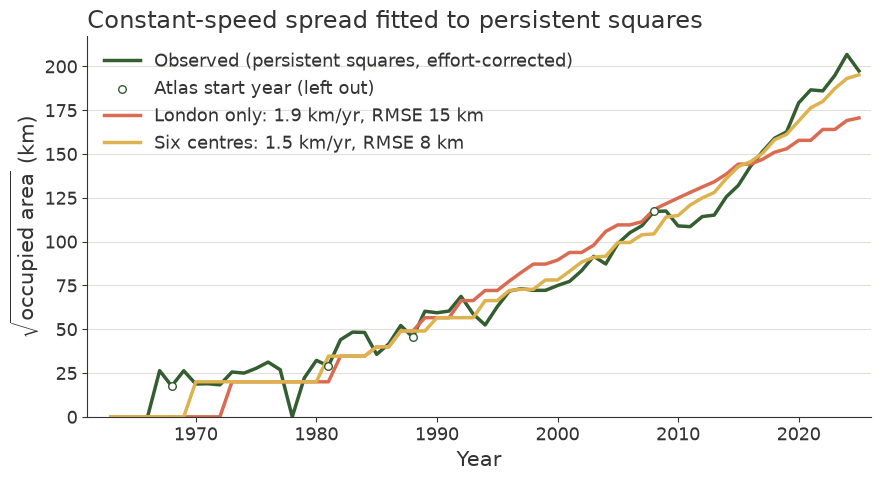

In [19]:
# Same plot as "Curves", fitted to the persistent-squares range
fig, ax = plt.subplots(figsize=(9, 5))

used = ~persistent_curve.index.isin(ATLAS_START_YEARS)
ax.plot(persistent_curve.index, persistent_curve, color=OBSERVED, linewidth=2.5,
        label="Observed (persistent squares, effort-corrected)")
ax.scatter(persistent_curve.index[~used], persistent_curve[~used], facecolors="white", edgecolors=OBSERVED,
           s=30, zorder=3, label="Atlas start year (left out)")
for name, colour in [("London only", LONDON_ONLY), ("Six centres", SIX_CENTRES)]:
    f = fits_p[name]
    ax.plot(curves_p[name].index, curves_p[name], color=colour, linewidth=2.5,
            label=f"{name}: {f['speed']:.1f} km/yr, RMSE {rmse_from_sse(f['sse']):.0f} km")

ax.set_xlim(FIRST_YEAR - 2, LAST_YEAR + 1)
ax.set_ylim(bottom=0)
ax.set_xlabel("Year")
ax.set_ylabel(r"$\sqrt{\text{occupied area}}$ (km)")
ax.set_title("Constant-speed spread fitted to persistent squares")
ax.legend(frameon=False, loc="upper left", fontsize=13)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "spread_model_curves_persistent.png", dpi=200)

**Result.** Fitted to persistent squares, the six-centre model gives the same picture:

| | All squares (main fit) | Persistent squares |
|---|---|---|
| Six centres: speed, RMSE | 1.5 km/yr, 8.1 km | 1.5 km/yr, 7.8 km |
| London only: speed, RMSE | 2.1 km/yr, 15.2 km | 1.9 km/yr, 14.6 km |
| Observed rate 1970–2009 → 2010–2025 | 1.6 → 4.0 km/yr | 1.3 → 4.0 km/yr |
| Share of the speed-up explained (2010 / 2007 / 2005 to 2025) | 59 / 72 / 80% | 64 / 73 / 78% |

The speed is the same, six centres again fit about twice as well as London alone, and the new centres account for about 60 to 80% of the speed-up either way. So the result does not depend on one-off sightings. The start years move again (London 1970, Glasgow 1997, the others 2003–2005), another sign that they are poorly determined.

## Conclusions

**Six centres fit much better than London alone.**

| | London only | Six centres |
|---|---|---|
| Speed | 2.1 km/yr | 1.5 km/yr |
| Start years | London 1970 | London 1963, Birmingham 1995, Glasgow 1996, Manchester 2002, Nottingham 2003, Newcastle 2004 |
| RMSE 1970–2025 | 15.2 km | 8.1 km |
| RMSE 1970–2009 / 2010–2025 | 11.3 / 21.6 km | 7.2 / 9.9 km |

- **Speed:** 1.5 km/yr (near-best fits 1.5–1.6 km/yr), matching the 1.6 km/yr before 2010 from `04`. London alone needs a higher speed (2.1 km/yr) and still bends the wrong way after 2010, because its circle reaches the coast.
- **Start years:** London starts at the lower bound (1963, 5 years before its first record), so the fit would place it even earlier. The other start years are poorly determined: near-best fits put Manchester at 2001–2006, Birmingham 1995–2006, Newcastle 1991–2006, Nottingham 1990–2003 and Glasgow 1996–1997. Consistent is the order: London first, the others from about 1990 to the mid-2000s. Because the fit only sees the total area, it shares the area among the centres almost arbitrarily: Glasgow gets a 44 km circle by 2025, much larger than its cluster (about 14 km), while Manchester gets 35 km against a cluster of about 44 km.
- **The acceleration:** with one constant speed, the six-centre curve's own spread rate rises from 1.7 km/yr (1970–2009) to 3.1 km/yr (2010–2025), against 1.6 → 4.0 observed: it reproduces 1.4 of the 2.4 km/yr speed-up. The share depends on the window, because of the stall after Bird Atlas 2007–11: 59% for 2010–2025, 72% for 2007–2025, 80% for 2005–2025. So: about 60 to 80%. The share is the model's own speed-up over the observed one, each against the rate before the window; measuring against the London-only fit instead (one compromise speed for the whole period) gives almost the same, 60 / 73 / 81%.
- **Choice of centres:** an earlier version used the five largest cities (London, Birmingham, Manchester, Glasgow, Cardiff), fitted with 2008 still in: RMSE 8.8 km against 8.4 km for these six, 2.8 km/yr after 2010, and similar map agreement (63% of persistent 2025 squares inside the circles, against 64% now). With start years fitted to the total area, the choice of centres matters little; the map-based centres are better justified.
- **Maps:** about half of the observed squares lie inside the circles (52% in 2025; 64% of persistent squares). London fits well. 262 of 543 observed squares in 2025 lie outside all six circles: groups near Liverpool, Leeds, Southampton, Bristol and East Kent, and many scattered squares.
- **Persistent squares:** fitted to the range from persistent squares only, the speed (1.5 km/yr) and the share of the speed-up explained (64 / 73 / 78%) hardly change; see "Check: fit to persistent squares".
- **Next step:** fit the start years to the maps (each centre's circle against the observed squares around it) instead of the total area. That would pin down the start years and size the circles correctly.

**Caveats:** the observer effect (cities have more birdwatchers and more escapes; not corrected); the start years are fitted to the total area only; centres placed at city coordinates; circles ignore sea and habitat.